In [1]:
import duckdb as db
import numpy as np
import matplotlib.pyplot as plt

import datetime as dt

In [2]:
data = db.query("SELECT run_date, name, distance_km, avg_pace_min_per_km FROM 'data/runs.parquet' WHERE location = 'outdoors'").to_df()

In [3]:
data[data['run_date'] > "2026-09-14"].head()

,run_date,name,distance_km,avg_pace_min_per_km
33,2026-09-17,Nike Run Club: 4K Starting Lines,6.62,8.38
34,2026-09-17,Colour run!,0.81,6.62
35,2026-09-17,Nike Run Club: Seven Minute Intervals,1.99,6.03
36,2026-09-20,Nike Run Club: 8K Head Starts,8.00,6.69
37,2026-09-21,Nike Run Club: 11 Weeks to Go,2.67,7.18


In [4]:
dates = data['run_date'].values.tolist()
dates = [dt.datetime.strftime(date, '%Y-%m-%d') for date in dates]

In [5]:
run_types = {}
#for date in dates:
#    run_types[date] = "unknown"
#    #print(date)

In [10]:
run_types['2026-05-18'] = "recovery"
run_types['2026-05-29'] = "long"
run_types['2026-06-04'] = "intervals"
run_types['2026-06-07'] = "recovery"
run_types['2026-06-11'] = "fartlek"
run_types['2026-06-12'] = "recovery"
run_types['2026-06-15'] = "recovery"
run_types['2026-06-22'] = "recovery"
run_types['2026-06-25'] = "recovery"
run_types['2026-06-26'] = "recovery"

# 10k training begins
run_types['2026-06-29'] = "recovery"
run_types['2026-07-06'] = "recovery"
run_types['2026-07-16'] = "tempo"

run_types['2026-08-02'] = "long"
run_types['2026-08-04'] = "recovery"
run_types['2026-08-06'] = "hill"
run_types['2026-08-07'] = "recovery"
run_types['2026-08-09'] = "long"
run_types['2026-08-11'] = "recovery"
run_types['2026-08-13'] = "fartlek"
run_types['2026-08-17'] = "recovery"
run_types['2026-08-19'] = "recovery"
run_types['2026-08-22'] = "race"
run_types['2026-08-24'] = "recovery"
run_types['2026-08-25'] = "recovery"
run_types['2026-08-27'] = "fartlek"
run_types['2026-08-28'] = "recovery"
run_types['2026-08-31'] = "recovery"

run_types['2026-09-01'] = "tempo"
run_types['2026-09-03'] = "recovery"
run_types['2026-09-04'] = "recovery"
run_types['2026-09-05'] = "race"

# Half-marathon training begins
run_types['2026-09-14'] = "recovery"
run_types['2026-09-17_1'] = "intervals"
run_types['2026-09-17_2'] = "fun"
run_types['2026-09-17_3'] = "recovery"
run_types['2026-09-20'] = "long"
run_types['2026-09-21'] = "recovery"
run_types['2026-09-22'] = "recovery"
run_types['2026-09-27'] = "long"
run_types['2026-09-28'] = "recovery"

run_types['2026-10-01'] = "tempo"
run_types['2026-10-02'] = "recovery"
run_types['2026-10-04'] = "long"
run_types['2026-10-05'] = "recovery"
run_types['2026-10-06'] = "recovery"
run_types['2026-10-08'] = "fartlek"
run_types['2026-10-11'] = "long"
run_types['2026-10-12'] = "recovery"
run_types['2026-10-15'] = "tempo"
run_types['2026-10-18'] = "long"
run_types['2026-10-19'] = "recovery"
run_types['2026-10-22'] = "tempo"
run_types['2026-10-23'] = "recovery"
run_types['2026-10-24'] = "long"
run_types['2026-10-26'] = "recovery"
run_types['2026-10-28'] = "intervals"
run_types['2026-10-29'] = "recovery"
run_types['2026-10-31'] = "long"

run_types['2026-11-02'] = "recovery"
run_types['2026-11-04'] = "fartlek"
run_types['2026-11-05'] = "recovery"
run_types['2026-11-08'] = "long"

In [11]:
run_types_list = []
for key, value in run_types.items():
    run_types_list.append(value)

In [12]:
len(run_types_list)

63

In [13]:
data["run_type"] = run_types_list

In [14]:
data[data['run_type'] == 'unknown']

,run_date,name,distance_km,avg_pace_min_per_km,run_type


In [15]:
d = np.linspace(0.5, 42, 200)

paces = []
for minutes in (15, 30, 45, 60, 90, 120, 180, 240):
    pace_ = minutes / d
    paces.append(pace_)

/Users/blair.kirkpatrick/repos/running/.venv/lib/python3.14/site-packages/pandas/plotting/_matplotlib/core.py:1427: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(


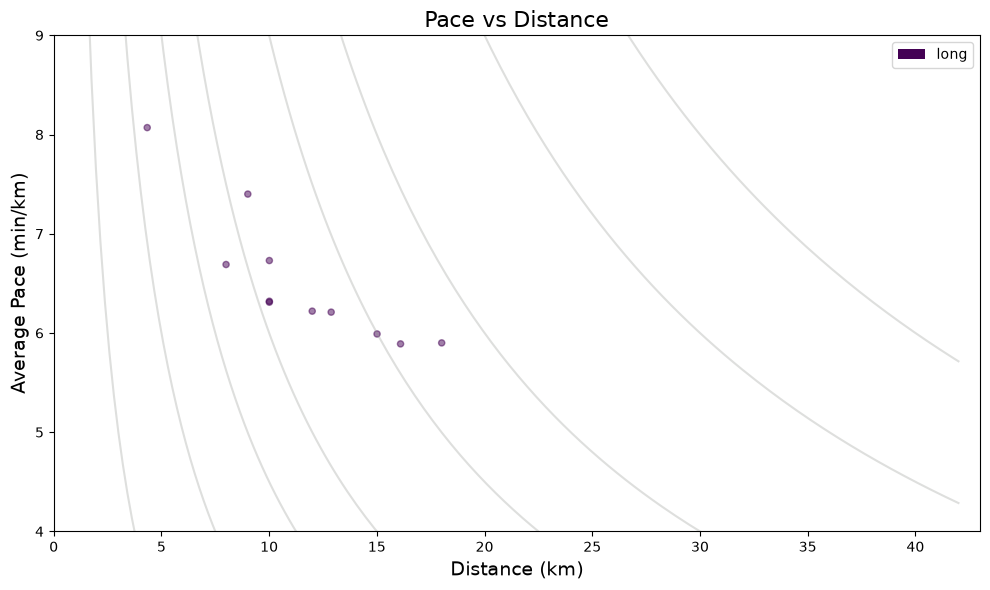

In [18]:
fig,ax = plt.subplots(1, 1, figsize=(10,6), dpi=100)
#ax.scatter(data['distance_km'], data['avg_pace_min_per_km'], alpha=0.5)
data[data["run_type"] == "long"].plot.scatter(x='distance_km', y='avg_pace_min_per_km', c='run_type', colormap='viridis', alpha=0.5, ax=ax)

for i, j in enumerate(paces):
    ax.plot(d, j, c='xkcd:gray', linestyle='-', alpha=0.3)

ax.set_xlabel('Distance (km)', fontsize=14)
ax.set_ylabel('Average Pace (min/km)', fontsize=14)
ax.set_title('Pace vs Distance', fontsize=16)

ax.set_xlim(0, 43)
ax.set_ylim(4, 9)

fig.tight_layout();

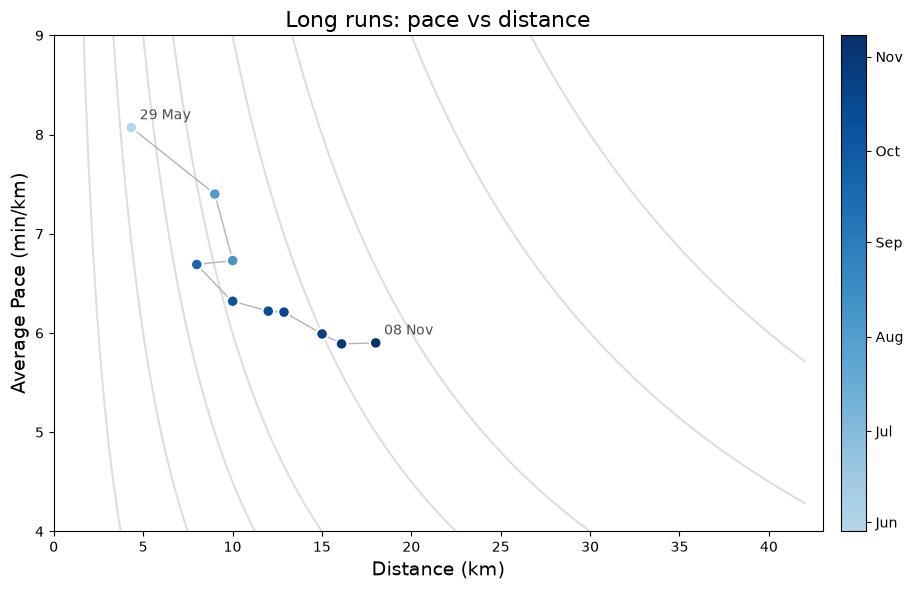

In [19]:
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap

long_runs = data[data["run_type"] == "long"].sort_values("run_date")
t = mdates.date2num(long_runs["run_date"])
# Blues, with the near-white end trimmed so early runs stay visible
cmap = ListedColormap(plt.get_cmap("Blues")(np.linspace(0.3, 1, 256)))

fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

for p in paces:
    ax.plot(d, p, c="xkcd:gray", alpha=0.3, zorder=1)

# chronological path
ax.plot(long_runs["distance_km"], long_runs["avg_pace_min_per_km"], c="0.7", lw=1, zorder=2)

sc = ax.scatter(long_runs["distance_km"], long_runs["avg_pace_min_per_km"], c=t, cmap=cmap,
                s=70, edgecolor="white", linewidth=1.5, zorder=3)

cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.ax.yaxis.set_major_locator(mdates.MonthLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%b"))

# label only the first and last runs
for _, r in long_runs.iloc[[0, -1]].iterrows():
    ax.annotate(r["run_date"].strftime("%d %b"), (r["distance_km"], r["avg_pace_min_per_km"]),
                xytext=(6, 6), textcoords="offset points", fontsize=10, color="0.3")

ax.set_xlabel("Distance (km)", fontsize=14)
ax.set_ylabel("Average Pace (min/km)", fontsize=14)
ax.set_title("Long runs: pace vs distance", fontsize=16)
ax.set_xlim(0, 43)
ax.set_ylim(4, 9)
fig.tight_layout();


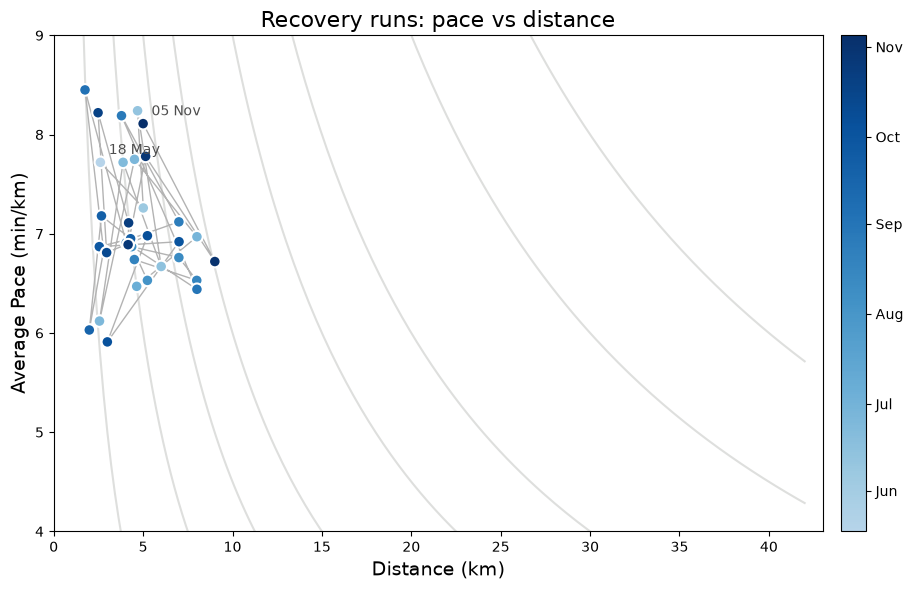

In [20]:
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap

recovery_runs = data[data["run_type"] == "recovery"].sort_values("run_date")


t = mdates.date2num(recovery_runs["run_date"])
# Blues, with the near-white end trimmed so early runs stay visible
cmap = ListedColormap(plt.get_cmap("Blues")(np.linspace(0.3, 1, 256)))

fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

for p in paces:
    ax.plot(d, p, c="xkcd:gray", alpha=0.3, zorder=1)

# chronological path
ax.plot(recovery_runs["distance_km"], recovery_runs["avg_pace_min_per_km"], c="0.7", lw=1, zorder=2)

sc = ax.scatter(recovery_runs["distance_km"], recovery_runs["avg_pace_min_per_km"], c=t, cmap=cmap,
                s=70, edgecolor="white", linewidth=1.5, zorder=3)

cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.ax.yaxis.set_major_locator(mdates.MonthLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%b"))

# label only the first and last runs
for _, r in recovery_runs.iloc[[0, -1]].iterrows():
    ax.annotate(r["run_date"].strftime("%d %b"), (r["distance_km"], r["avg_pace_min_per_km"]),
                xytext=(6, 6), textcoords="offset points", fontsize=10, color="0.3")

ax.set_xlabel("Distance (km)", fontsize=14)
ax.set_ylabel("Average Pace (min/km)", fontsize=14)
ax.set_title("Recovery runs: pace vs distance", fontsize=16)
ax.set_xlim(0, 43)
ax.set_ylim(4, 9)
fig.tight_layout();
